# XAI - Lending Club Loan - Accepted dataset analysis

In [1]:
import importlib.util

if importlib.util.find_spec("hvplot") is None:
    get_ipython().run_line_magic("pip", "install -q hvplot")

### 1. Setup & Inspect Data Dictionary vs. Dataset Schema

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np

pd.set_option("display.max_rows", 200)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 140)

DATA_DIR = Path(".")
DATASET_PATH = DATA_DIR / "dataset" / "accepted_2007_to_2018q4.csv" / "accepted_2007_to_2018Q4.csv"
DICT_PATH = DATA_DIR / "LCDataDictionary(LoanStats).csv"
NUMERICAL_DICT_PATH = DATA_DIR / "LCDataDictionary(LoanStats) - numerical only.csv"

# Known LendingClub dictionary vs. CSV header discrepancy
COLUMN_ALIASES = {
    "verified_status_joint": "verification_status_joint",
}

def load_clean_data_dictionary(path: Path) -> pd.DataFrame:
    """Load data dictionary with encoding fallback, strip whitespace/NBSP, and drop empty columns/rows."""
    for enc in ("utf-8", "cp1252", "latin1"):
        try:
            df = pd.read_csv(path, encoding=enc)
            break
        except UnicodeDecodeError:
            continue
    else:
        raise ValueError(f"Could not decode {path}")

    # Keep only core dictionary columns so re-running this notebook stays idempotent
    core_cols = [c for c in ("LoanStatNew", "Description") if c in df.columns]
    df = df[core_cols].copy()
    df = df.dropna(how="all").reset_index(drop=True)
    df["LoanStatNew"] = df["LoanStatNew"].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )
    return df

dd_df = load_clean_data_dictionary(DICT_PATH)
dataset_cols = pd.read_csv(DATASET_PATH, nrows=0).columns.tolist()

dd_feature_names = set(dd_df["LoanStatNew"].dropna())
mapped_dd_names = {COLUMN_ALIASES.get(c, c) for c in dd_feature_names}
ds_col_set = set(dataset_cols)

print(f"Dictionary rows (total non-empty): {len(dd_df)}")
print(f"Dictionary feature names:          {len(dd_feature_names)}")
print(f"Dataset columns:                   {len(dataset_cols)}")
print(f"In dataset but missing from dict:  {sorted(ds_col_set - mapped_dd_names)}")
print(f"In dict but missing from dataset:  {sorted(mapped_dd_names - ds_col_set)}")
dd_df.head(10)

Dictionary rows (total non-empty): 152
Dictionary feature names:          151
Dataset columns:                   151
In dataset but missing from dict:  []
In dict but missing from dataset:  []
Out[2]: 
            LoanStatNew                                                                      Description
0        acc_now_delinq                  The number of accounts on which the borrower is now delinquent.
1  acc_open_past_24mths                                       Number of trades opened in past 24 months.
2            addr_state                       The state provided by the borrower in the loan application
3              all_util                                            Balance to credit limit on all trades
4            annual_inc    The self-reported annual income provided by the borrower during registration.
5      annual_inc_joint  The combined self-reported annual income provided by the co-borrowers during...
6      application_type  Indicates whether the loan is an indiv

,LoanStatNew,Description
0,acc_now_delinq,The number of accounts on which the borrower is now delinquent.
1,acc_open_past_24mths,Number of trades opened in past 24 months.
2,addr_state,The state provided by the borrower in the loan application
3,all_util,Balance to credit limit on all trades
4,annual_inc,The self-reported annual income provided by the borrower during registration.
5,annual_inc_joint,The combined self-reported annual income provided by the co-borrowers during...
6,application_type,Indicates whether the loan is an individual application or a joint applicati...
7,avg_cur_bal,Average current balance of all accounts
8,bc_open_to_buy,Total open to buy on revolving bankcards.
9,bc_util,Ratio of total current balance to high credit/credit limit for all bankcard ...


### 2. Systematic Column Type Profiling Across the Full Dataset

We stream the entire ~1.67 GB `accepted_2007_to_2018Q4.csv` file in chunks (`chunksize=200_000`) and check every non-null value in each column:
- `is_numerical`: `True` iff the column has at least one non-null value AND 100% of non-null values are numeric (either native numeric dtype or parseable via `pd.to_numeric`).
- `inferred_type`: nominal classification (`numerical`, `date`, `categorical_or_text`, `mixed`, `empty`).
- `dataset_dtype`: observed pandas dtype(s) across chunks.

In [3]:
def profile_dataset_columns(csv_path: Path, chunksize: int = 200_000) -> pd.DataFrame:
    """Scan all rows of csv_path in chunks and systematically profile column data types."""
    cols = pd.read_csv(csv_path, nrows=0).columns.tolist()
    stats = {
        c: {
            "non_null_count": 0,
            "numeric_ok_count": 0,
            "date_ok_count": 0,
            "dtypes": set(),
            "samples": [],
            "non_numeric_samples": [],
        }
        for c in cols
    }
    total_rows = 0

    for chunk in pd.read_csv(csv_path, chunksize=chunksize, low_memory=False):
        total_rows += len(chunk)
        for c in cols:
            s = chunk[c]
            st = stats[c]
            st["dtypes"].add(str(s.dtype))
            nn = s.dropna()
            if len(nn) == 0:
                continue
            st["non_null_count"] += len(nn)
            if len(st["samples"]) < 3:
                for v in nn.unique()[:3]:
                    if v not in st["samples"]:
                        st["samples"].append(v)
                    if len(st["samples"]) >= 3:
                        break

            if pd.api.types.is_numeric_dtype(nn):
                st["numeric_ok_count"] += len(nn)
            else:
                coerced = pd.to_numeric(nn, errors="coerce")
                valid_num = coerced.notna()
                st["numeric_ok_count"] += int(valid_num.sum())

                if not valid_num.all():
                    if len(st["non_numeric_samples"]) < 3:
                        for v in nn[~valid_num].unique()[:3]:
                            if v not in st["non_numeric_samples"]:
                                st["non_numeric_samples"].append(v)
                            if len(st["non_numeric_samples"]) >= 3:
                                break
                    parsed_dates = pd.to_datetime(nn.astype(str), format="%b-%Y", errors="coerce")
                    st["date_ok_count"] += int(parsed_dates.notna().sum())

    records = []
    for c in cols:
        st = stats[c]
        nn_cnt = st["non_null_count"]
        num_cnt = st["numeric_ok_count"]
        date_cnt = st["date_ok_count"]
        dtypes_sorted = sorted(st["dtypes"])
        dataset_dtype = dtypes_sorted[0] if len(dtypes_sorted) == 1 else f"mixed({', '.join(dtypes_sorted)})"

        if nn_cnt == 0:
            inferred_type = "empty"
            is_numerical = False
        elif num_cnt == nn_cnt:
            inferred_type = "numerical"
            is_numerical = True
        elif date_cnt == nn_cnt:
            inferred_type = "date"
            is_numerical = False
        elif 0 < num_cnt < nn_cnt:
            inferred_type = "mixed"
            is_numerical = False
        else:
            inferred_type = "categorical_or_text"
            is_numerical = False

        records.append({
            "dataset_column": c,
            "total_rows": total_rows,
            "non_null_count": nn_cnt,
            "null_pct": round(100.0 * (total_rows - nn_cnt) / total_rows, 2),
            "dataset_dtype": dataset_dtype,
            "inferred_type": inferred_type,
            "is_numerical": is_numerical,
            "samples": st["samples"],
            "non_numeric_samples": st["non_numeric_samples"],
        })

    return pd.DataFrame(records)

profile_df = profile_dataset_columns(DATASET_PATH)
print(f"Total rows scanned: {profile_df['total_rows'].iloc[0]:,}")
print("\nInferred type counts:")
print(profile_df["inferred_type"].value_counts())
print("\nis_numerical counts:")
print(profile_df["is_numerical"].value_counts())

print("\nNon-numerical columns (filtered out of numerical-only CSV):")
display(profile_df[~profile_df["is_numerical"]][["dataset_column", "non_null_count", "null_pct", "dataset_dtype", "inferred_type", "samples", "non_numeric_samples"]])

Total rows scanned: 2,260,701

Inferred type counts:
inferred_type
numerical              112
categorical_or_text     24
date                    11
mixed                    3
empty                    1
Name: count, dtype: int64

is_numerical counts:
is_numerical
True     112
False     39
Name: count, dtype: int64

Non-numerical columns (filtered out of numerical-only CSV):


,dataset_column,non_null_count,null_pct,dataset_dtype,inferred_type,samples,non_numeric_samples
0,id,2260701,0.00,"mixed(int64, object)",mixed,"[68407277, 68355089, 68341763]","[Total amount funded in policy code 1: 6417608175, Total amount funded in po..."
1,member_id,0,100.00,float64,empty,[],[]
5,term,2260668,0.00,object,categorical_or_text,"[ 36 months, 60 months]","[ 36 months, 60 months]"
8,grade,2260668,0.00,object,categorical_or_text,"[C, B, F]","[C, B, F]"
9,sub_grade,2260668,0.00,object,categorical_or_text,"[C4, C1, B4]","[C4, C1, B4]"
10,emp_title,2093699,7.39,object,mixed,"[leadman, Engineer, truck driver]","[leadman, Engineer, truck driver]"
11,emp_length,2113761,6.50,object,categorical_or_text,"[10+ years, 3 years, 4 years]","[10+ years, 3 years, 4 years]"
12,home_ownership,2260668,0.00,object,categorical_or_text,"[MORTGAGE, RENT, OWN]","[MORTGAGE, RENT, OWN]"
14,verification_status,2260668,0.00,object,categorical_or_text,"[Not Verified, Source Verified, Verified]","[Not Verified, Source Verified, Verified]"
15,issue_d,2260668,0.00,object,date,"[Dec-2015, Nov-2015, Oct-2015]","[Dec-2015, Nov-2015, Oct-2015]"


### 3. Annotate `LCDataDictionary(LoanStats).csv` and Filter `LCDataDictionary(LoanStats) - numerical only.csv`

In [4]:
# Map dictionary rows to dataset profile using COLUMN_ALIASES
dd_annotated = dd_df.copy()
dd_annotated["_lookup_col"] = dd_annotated["LoanStatNew"].map(
    lambda x: COLUMN_ALIASES.get(x, x) if isinstance(x, str) else np.nan
)

profile_lookup = profile_df.set_index("dataset_column")
dd_annotated["dataset_dtype"] = dd_annotated["_lookup_col"].map(profile_lookup["dataset_dtype"])
dd_annotated["inferred_type"] = dd_annotated["_lookup_col"].map(profile_lookup["inferred_type"])
dd_annotated["is_numerical"] = dd_annotated["_lookup_col"].map(profile_lookup["is_numerical"]).fillna(False).astype(bool)
dd_annotated = dd_annotated.drop(columns=["_lookup_col"])

# Save updated full dictionary (UTF-8, clean columns)
dd_annotated.to_csv(DICT_PATH, index=False, encoding="utf-8")

# Filter strictly to numerical columns and save numerical-only dictionary
dd_numerical = dd_annotated[dd_annotated["is_numerical"]].reset_index(drop=True)
dd_numerical.to_csv(NUMERICAL_DICT_PATH, index=False, encoding="utf-8")

# Verification
verify_full = pd.read_csv(DICT_PATH)
verify_num = pd.read_csv(NUMERICAL_DICT_PATH)

assert len(verify_num) == int(profile_df["is_numerical"].sum()), (
    f"Mismatch: {len(verify_num)} vs {profile_df['is_numerical'].sum()}"
)
assert verify_num["is_numerical"].all()
assert set(verify_num["LoanStatNew"]) == set(profile_df.loc[profile_df["is_numerical"], "dataset_column"])

print(f"Saved full annotated dictionary: {DICT_PATH.name} ({len(verify_full)} rows, cols={list(verify_full.columns)})")
print(f"Saved numerical-only dictionary: {NUMERICAL_DICT_PATH.name} ({len(verify_num)} rows, cols={list(verify_num.columns)})")
display(verify_full.head(15))
display(verify_num.head(15))

Saved full annotated dictionary: LCDataDictionary(LoanStats).csv (152 rows, cols=['LoanStatNew', 'Description', 'dataset_dtype', 'inferred_type', 'is_numerical'])
Saved numerical-only dictionary: LCDataDictionary(LoanStats) - numerical only.csv (112 rows, cols=['LoanStatNew', 'Description', 'dataset_dtype', 'inferred_type', 'is_numerical'])


<ipython-input-4-7d4b81889b98>:10: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  dd_annotated["is_numerical"] = dd_annotated["_lookup_col"].map(profile_lookup["is_numerical"]).fillna(False).astype(bool)


,LoanStatNew,Description,dataset_dtype,inferred_type,is_numerical
0,acc_now_delinq,The number of accounts on which the borrower is now delinquent.,float64,numerical,True
1,acc_open_past_24mths,Number of trades opened in past 24 months.,float64,numerical,True
2,addr_state,The state provided by the borrower in the loan application,object,categorical_or_text,False
3,all_util,Balance to credit limit on all trades,float64,numerical,True
4,annual_inc,The self-reported annual income provided by the borrower during registration.,float64,numerical,True
5,annual_inc_joint,The combined self-reported annual income provided by the co-borrowers during...,float64,numerical,True
6,application_type,Indicates whether the loan is an individual application or a joint applicati...,object,categorical_or_text,False
7,avg_cur_bal,Average current balance of all accounts,float64,numerical,True
8,bc_open_to_buy,Total open to buy on revolving bankcards.,float64,numerical,True
9,bc_util,Ratio of total current balance to high credit/credit limit for all bankcard ...,float64,numerical,True


,LoanStatNew,Description,dataset_dtype,inferred_type,is_numerical
0,acc_now_delinq,The number of accounts on which the borrower is now delinquent.,float64,numerical,True
1,acc_open_past_24mths,Number of trades opened in past 24 months.,float64,numerical,True
2,all_util,Balance to credit limit on all trades,float64,numerical,True
3,annual_inc,The self-reported annual income provided by the borrower during registration.,float64,numerical,True
4,annual_inc_joint,The combined self-reported annual income provided by the co-borrowers during...,float64,numerical,True
5,avg_cur_bal,Average current balance of all accounts,float64,numerical,True
6,bc_open_to_buy,Total open to buy on revolving bankcards.,float64,numerical,True
7,bc_util,Ratio of total current balance to high credit/credit limit for all bankcard ...,float64,numerical,True
8,chargeoff_within_12_mths,Number of charge-offs within 12 months,float64,numerical,True
9,collection_recovery_fee,post charge off collection fee,float64,numerical,True


---
## 4. Two-Step XAI Problem Architecture (`description.md`) & Data Hygiene Rules

Following `description.md`, our problem has **two sequential decision stages** with **distinct feature spaces**:
1. **Stage 1 — Application Gate (`Accepted` vs. `Rejected`):**
   - Why we **cannot** use Accepted-only features (like `grade`, `int_rate`, `term`) here: rejected applicants never received a loan or LendingClub grade, so any unseen applicant must be evaluated strictly on the **shared pre-decision features** common to both `accepted_2007_to_2018Q4.csv` and `rejected_2007_to_2018Q4.csv`.
   - **Balanced sampling:** Real ratio is ~2.26M Accepted vs. ~27.6M Rejected (~7.6% acceptance). For clean training and unbiased attribution, we construct a **50/50 balanced sample** (25,000 Accepted + 25,000 Rejected = 50,000 rows) restricted to `2007–2014` where both datasets reliably record `Risk_Score` / FICO.
2. **Stage 2 — Default Risk Among Accepted Borrowers (`Fully Paid` vs. `Default / Charged Off`):**
   - **Matured cohort filtering (eliminating newer-date right-censoring bias):** At the Dec 2018 snapshot, 2016–2018 loans (especially 60-month loans after 2013 and 36-month loans after 2015) have not reached maturity. Keeping only **matured loans** (`36 months` issued `<= 2015-12-31`, `60 months` issued `<= 2013-12-31`) from **2013–2015** (when modern credit-bureau fields are ~99%+ populated) prevents right-censoring bias and 2012-era missingness confounding.
   - **Column-by-column curation:** Parallel to `lending-club-loan-defaulters-prediction.ipynb`, we audit missingness, redundancy, leakage, and domain relevance to select 34 clean origination features (keeping `grade`, `sub_grade`, `emp_length`, etc., and dropping post-origination leakage).

Both stages produce reproducible **Train (60%) / Validation (20%) / Test (20%)** splits plus a small **TabFM (`TabPFN`) subset (3,000 Train / 1,000 Val / 2,000 Test)** saved under `processed/`.

In [5]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid", context="notebook")

RANDOM_STATE = 42
REJECTED_PATH = DATA_DIR / "dataset" / "rejected_2007_to_2018q4.csv" / "rejected_2007_to_2018Q4.csv"
PROCESSED_DIR = DATA_DIR / "processed"
PROCESSED_DIR.mkdir(exist_ok=True)

GRADE_ORDER = ["A", "B", "C", "D", "E", "F", "G"]
SUB_GRADE_ORDER = [f"{g}{n}" for g in GRADE_ORDER for n in range(1, 6)]
EMP_LENGTH_ORDER = [
    "< 1 year", "1 year", "2 years", "3 years", "4 years", "5 years",
    "6 years", "7 years", "8 years", "9 years", "10+ years",
]
EMP_LENGTH_MAP = {label: float(i) for i, label in enumerate(EMP_LENGTH_ORDER)}

US_STATES = {
    "AL","AK","AZ","AR","CA","CO","CT","DE","FL","GA","HI","ID","IL","IN","IA","KS","KY",
    "LA","ME","MD","MA","MI","MN","MS","MO","MT","NE","NV","NH","NJ","NM","NY","NC","ND",
    "OH","OK","OR","PA","RI","SC","SD","TN","TX","UT","VT","VA","WA","WV","WI","WY","DC",
}

def parse_emp_length(series: pd.Series) -> pd.Series:
    return series.astype("object").map(EMP_LENGTH_MAP).astype(float)

def save_3way_and_tfm_splits(
    df: pd.DataFrame,
    target_col: str,
    stratify_col: pd.Series,
    prefix: str,
    tfm_sizes: tuple[int, int, int] = (3000, 1000, 2000),
) -> dict:
    """Create stratified 60/20/20 Train/Val/Test splits and nested small TabFM subsets."""
    tr, tmp, strat_tr, strat_tmp = train_test_split(
        df, stratify_col, test_size=0.40, stratify=stratify_col, random_state=RANDOM_STATE
    )
    va, te = train_test_split(
        tmp, test_size=0.50, stratify=strat_tmp, random_state=RANDOM_STATE
    )

    tr.to_csv(PROCESSED_DIR / f"{prefix}_train.csv", index=False)
    va.to_csv(PROCESSED_DIR / f"{prefix}_val.csv", index=False)
    te.to_csv(PROCESSED_DIR / f"{prefix}_test.csv", index=False)

    # Nested small subsets strictly drawn from each split for TabPFN experiments
    n_tr, n_va, n_te = tfm_sizes
    tfm_tr, _ = train_test_split(tr, train_size=min(n_tr, len(tr) - 1), stratify=tr[target_col], random_state=RANDOM_STATE)
    tfm_va, _ = train_test_split(va, train_size=min(n_va, len(va) - 1), stratify=va[target_col], random_state=RANDOM_STATE)
    tfm_te, _ = train_test_split(te, train_size=min(n_te, len(te) - 1), stratify=te[target_col], random_state=RANDOM_STATE)

    tfm_tr.to_csv(PROCESSED_DIR / f"{prefix}_tfm_train.csv", index=False)
    tfm_va.to_csv(PROCESSED_DIR / f"{prefix}_tfm_val.csv", index=False)
    tfm_te.to_csv(PROCESSED_DIR / f"{prefix}_tfm_test.csv", index=False)

    summary = {
        "train": (len(tr), round(tr[target_col].mean(), 4)),
        "val": (len(va), round(va[target_col].mean(), 4)),
        "test": (len(te), round(te[target_col].mean(), 4)),
        "tfm_train": (len(tfm_tr), round(tfm_tr[target_col].mean(), 4)),
        "tfm_val": (len(tfm_va), round(tfm_va[target_col].mean(), 4)),
        "tfm_test": (len(tfm_te), round(tfm_te[target_col].mean(), 4)),
    }
    return summary

---
## 5. Stage 1 Dataset — Shared Features, Anomaly Removal & Balanced 50/50 Splits

Between the **9 columns** in `rejected_2007_to_2018Q4.csv` and **151 columns** in `accepted_2007_to_2018Q4.csv`:
- **Clean shared features kept (5):** `loan_amnt` (`Amount Requested`), `dti` (`Debt-To-Income Ratio`), `risk_score` (`Risk_Score` vs. FICO midpoint), `emp_length_years` (`Employment Length` vs. `emp_length`), `state` (`State` vs. `addr_state`).
- **Excluded:** `Policy Code` (0 vs. 1 label leak), `Zip Code` (masked prefix/sensitive proxy), `Loan Title` (unstructured text in Rejected vs. standardized categories in Accepted), `Application Date` / `issue_d` (kept only for cohort filtering `2007–2014`, not as a causal applicant feature).
- **Contradiction & missingness filtering (applied symmetrically):**
  - Restrict to `2007–2014` (before Rejected stopped logging `Risk_Score` for ~80–93% of applications).
  - Remove `loan_amnt <= 0`, `dti < 0` (`-1%` sentinel in Rejected) or `dti > 100`, `risk_score` outside `[300, 850]` (drops `0` sentinels and `>850` anomalies), missing `emp_length`, and invalid/missing `state`.
  - Sample **25,000 Accepted + 25,000 Rejected** (50,000 total) and save 60/20/20 + TFM splits.

Stage 1 Accepted (2007-2014): raw=93,269 -> clean=89,108 (dropped 4,161 invalid/missing/duplicate rows)
Stage 1 Rejected (2007-2014): raw=69,002 -> clean=58,171 (dropped 10,831 invalid/missing/duplicate rows)
Saved Stage 1 splits: {'train': (30000, np.float64(0.5)), 'val': (10000, np.float64(0.5)), 'test': (10000, np.float64(0.5)), 'tfm_train': (3000, np.float64(0.5)), 'tfm_val': (1000, np.float64(0.5)), 'tfm_test': (2000, np.float64(0.5))}


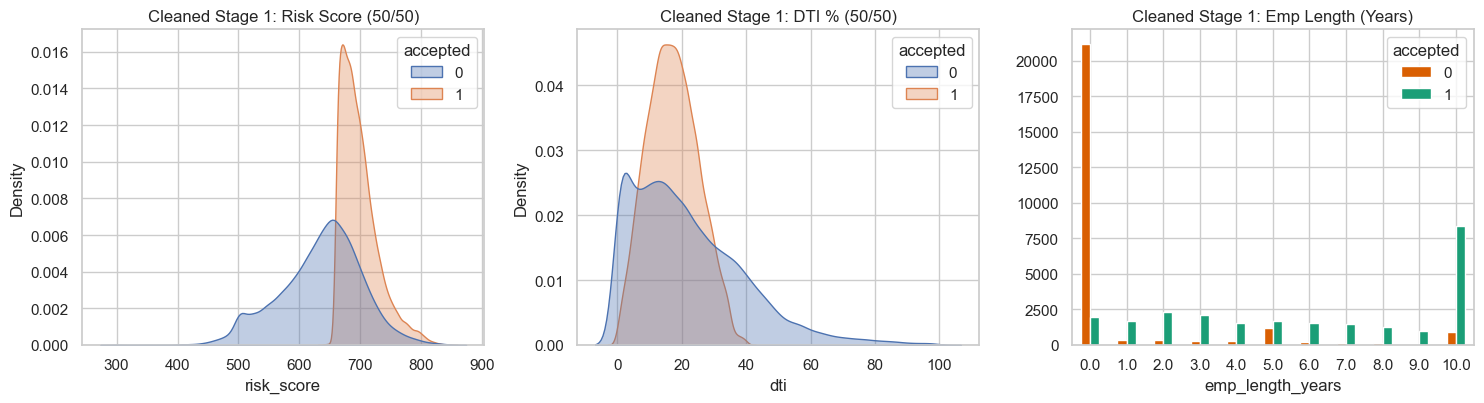

In [6]:
# Load strided samples covering 2007-2018 uniformly, then filter strictly to clean 2007-2014 rows
acc_s1_cols = [
    "loan_amnt", "dti", "fico_range_low", "fico_range_high",
    "emp_length", "addr_state", "issue_d", "loan_status",
]
acc_s1_raw = pd.read_csv(
    DATASET_PATH,
    usecols=acc_s1_cols,
    skiprows=lambda i: i > 0 and i % 5 != 0,
    low_memory=False,
).dropna(subset=["loan_status"])

rej_s1_raw = pd.read_csv(
    REJECTED_PATH,
    skiprows=lambda i: i > 0 and i % 50 != 0,
    low_memory=False,
)

acc_s1 = pd.DataFrame({
    "loan_amnt": pd.to_numeric(acc_s1_raw["loan_amnt"], errors="coerce"),
    "dti": pd.to_numeric(acc_s1_raw["dti"], errors="coerce"),
    "risk_score": 0.5 * (acc_s1_raw["fico_range_low"] + acc_s1_raw["fico_range_high"]),
    "emp_length_years": parse_emp_length(acc_s1_raw["emp_length"]),
    "state": acc_s1_raw["addr_state"].astype("string").str.strip(),
    "app_year": pd.to_datetime(acc_s1_raw["issue_d"], format="%b-%Y", errors="coerce").dt.year,
    "accepted": 1,
})

rej_s1 = pd.DataFrame({
    "loan_amnt": pd.to_numeric(rej_s1_raw["Amount Requested"], errors="coerce"),
    "dti": pd.to_numeric(rej_s1_raw["Debt-To-Income Ratio"].astype(str).str.rstrip("%"), errors="coerce"),
    "risk_score": pd.to_numeric(rej_s1_raw["Risk_Score"], errors="coerce"),
    "emp_length_years": parse_emp_length(rej_s1_raw["Employment Length"]),
    "state": rej_s1_raw["State"].astype("string").str.strip(),
    "app_year": pd.to_datetime(rej_s1_raw["Application Date"], errors="coerce").dt.year,
    "accepted": 0,
})

def clean_stage1_frame(df: pd.DataFrame, label: str) -> pd.DataFrame:
    df_win = df[df["app_year"].between(2007, 2014)].copy()
    valid = (
        (df_win["loan_amnt"] > 0)
        & (df_win["dti"].between(0, 100))
        & (df_win["risk_score"].between(300, 850))
        & (df_win["emp_length_years"].notna())
        & (df_win["state"].isin(US_STATES))
    )
    cleaned = df_win.loc[valid].drop_duplicates().reset_index(drop=True)
    print(
        f"Stage 1 {label:8s} (2007-2014): raw={len(df_win):,} -> clean={len(cleaned):,} "
        f"(dropped {len(df_win) - len(cleaned):,} invalid/missing/duplicate rows)"
    )
    return cleaned

acc_s1_clean = clean_stage1_frame(acc_s1, "Accepted")
rej_s1_clean = clean_stage1_frame(rej_s1, "Rejected")

# Balanced 50/50 subsample (25,000 each)
N_PER_CLASS = 25_000
s1_bal = pd.concat([
    acc_s1_clean.sample(n=N_PER_CLASS, random_state=RANDOM_STATE),
    rej_s1_clean.sample(n=N_PER_CLASS, random_state=RANDOM_STATE),
], ignore_index=True).sample(frac=1.0, random_state=RANDOM_STATE).reset_index(drop=True)

s1_feature_cols = ["loan_amnt", "dti", "risk_score", "emp_length_years", "state", "app_year", "accepted"]
s1_bal = s1_bal[s1_feature_cols]
strat_key_s1 = s1_bal["accepted"].astype(str) + "_" + s1_bal["app_year"].astype(int).astype(str)
s1_summary = save_3way_and_tfm_splits(s1_bal, "accepted", strat_key_s1, prefix="stage1")
print("Saved Stage 1 splits:", s1_summary)

# Quick Stage 1 distribution visual check on the cleaned 50/50 dataset
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
sns.kdeplot(data=s1_bal, x="risk_score", hue="accepted", common_norm=False, fill=True, alpha=0.35, ax=axes[0])
axes[0].set_title("Cleaned Stage 1: Risk Score (50/50)")
sns.kdeplot(data=s1_bal, x="dti", hue="accepted", common_norm=False, fill=True, alpha=0.35, ax=axes[1])
axes[1].set_title("Cleaned Stage 1: DTI % (50/50)")
s1_bal.groupby(["emp_length_years", "accepted"]).size().unstack().plot(kind="bar", ax=axes[2], color=["#d95f02", "#1b9e77"])
axes[2].set_title("Cleaned Stage 1: Emp Length (Years)")
axes[2].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

---
## 6. Stage 2 Dataset — Column Analysis, Matured Cohort Filtering & Anomaly Cleaning

Parallel to `lending-club-loan-defaulters-prediction.ipynb`, we systematically audit the Accepted columns on **matured, resolved loans**:
1. **Outcome & Maturity Filter:** Keep only `Fully Paid` (`0`) vs. `Charged Off` / `Default` (`1`), AND restrict to **matured loans** (`36 months` issued `2013–2015`, `60 months` issued `2013`) so newer loans haven't had artificially short time to default (right-censoring bias) and modern bureau features are ~99%+ populated.
2. **Column Selection Audit:** Out of 151 columns:
   - Exclude post-origination/leakage (`total_pymnt*`, `recoveries`, `last_pymnt_*`, `last_fico_range_*`, `hardship_*`, `settlement_*`, `out_prncp*`, `policy_code`, `id`, `member_id`, `url`, `desc`, `title`, `zip_code`).
   - Exclude >15% missing columns in 2013–2015 (e.g., `sec_app_*`, `*_joint`, `il_util`, `open_acc_6m`).
   - Prune exact/near-redundant duplicates (`funded_amnt`, `funded_amnt_inv` vs. `loan_amnt`; `fico_range_high` vs. `fico_range_low`; constant `disbursement_method`).
   - Retain **34 clean, high-value origination features** (explicitly keeping `grade`, `sub_grade`, `emp_length`, `int_rate`, `term_months`, `dti`, `annual_inc`, `fico_range_low`, `credit_history_years`, `purpose`, `home_ownership`, `verification_status`, `addr_state`, and core bureau metrics).
3. **Row-Level Contradiction Checks:** Verify and remove any impossible rows (`annual_inc <= 0`, `loan_amnt <= 0`, `dti < 0` or `> 100`, `revol_util > 150`, `open_acc > total_acc`, `earliest_cr_line > issue_d`, `fico_range_high < fico_range_low`, or missing core credit fields).

In [7]:
# Load stride-10 Accepted sample (~226k rows) and filter to matured 2013-2015 resolved loans
acc_raw = pd.read_csv(
    DATASET_PATH,
    skiprows=lambda i: i > 0 and i % 10 != 0,
    low_memory=False,
).dropna(subset=["loan_status"])

acc_raw["issue_dt"] = pd.to_datetime(acc_raw["issue_d"], format="%b-%Y", errors="coerce")
acc_raw["earliest_dt"] = pd.to_datetime(acc_raw["earliest_cr_line"], format="%b-%Y", errors="coerce")
acc_raw["term_months"] = acc_raw["term"].astype(str).str.extract(r"(\d+)")[0].astype(float)

PAID_STATUSES = {"Fully Paid", "Does not meet the credit policy. Status:Fully Paid"}
DEFAULT_STATUSES = {"Charged Off", "Default", "Does not meet the credit policy. Status:Charged Off"}

matured_mask = (
    (acc_raw["issue_dt"] >= "2013-01-01")
    & (
        ((acc_raw["term_months"] == 36) & (acc_raw["issue_dt"] <= "2015-12-31"))
        | ((acc_raw["term_months"] == 60) & (acc_raw["issue_dt"] <= "2013-12-31"))
    )
    & acc_raw["loan_status"].isin(PAID_STATUSES | DEFAULT_STATUSES)
)
s2_raw = acc_raw.loc[matured_mask].copy()
s2_raw["default"] = s2_raw["loan_status"].isin(DEFAULT_STATUSES).astype(int)
s2_raw["issue_year"] = s2_raw["issue_dt"].dt.year

# Engineered domain features
s2_raw["grade_num"] = s2_raw["grade"].map({g: i + 1 for i, g in enumerate(GRADE_ORDER)}).astype(float)
s2_raw["sub_grade_num"] = s2_raw["sub_grade"].map({sg: i + 1 for i, sg in enumerate(SUB_GRADE_ORDER)}).astype(float)
s2_raw["emp_length_years"] = parse_emp_length(s2_raw["emp_length"])
s2_raw["emp_length_missing"] = s2_raw["emp_length"].isna().astype(int)
s2_raw["credit_history_years"] = (s2_raw["issue_dt"] - s2_raw["earliest_dt"]).dt.days / 365.25
s2_raw["home_ownership"] = s2_raw["home_ownership"].replace({"ANY": "OTHER", "NONE": "OTHER"})

# Curated 34 origination features (column-analysis vetted)
STAGE2_SELECTED_FEATURES = [
    # Loan terms & LC pricing
    "loan_amnt", "term_months", "int_rate", "installment", "grade", "grade_num", "sub_grade_num",
    "purpose", "initial_list_status",
    # Borrower income, employment & burden
    "annual_inc", "dti", "emp_length_years", "emp_length_missing",
    "home_ownership", "verification_status", "addr_state",
    # Credit score & history depth
    "fico_range_low", "credit_history_years", "mo_sin_old_rev_tl_op", "mo_sin_rcnt_tl", "mort_acc",
    # Credit utilization, limits & recent activity
    "revol_bal", "revol_util", "bc_util", "percent_bc_gt_75", "total_bc_limit",
    "avg_cur_bal", "open_acc", "total_acc", "acc_open_past_24mths", "inq_last_6mths",
    "delinq_2yrs", "pub_rec", "pub_rec_bankruptcies",
]

# Contradiction & completeness checks
contradictions = {
    "loan_amnt <= 0": s2_raw["loan_amnt"] <= 0,
    "annual_inc <= 0": s2_raw["annual_inc"] <= 0,
    "dti < 0 or > 100": ~s2_raw["dti"].between(0, 100),
    "revol_util < 0 or > 150": ~s2_raw["revol_util"].between(0, 150),
    "fico_high < fico_low": s2_raw["fico_range_high"] < s2_raw["fico_range_low"],
    "open_acc > total_acc": s2_raw["open_acc"] > s2_raw["total_acc"],
    "earliest_cr_line > issue_d": s2_raw["credit_history_years"] < 0,
    "invalid state": ~s2_raw["addr_state"].isin(US_STATES),
}
print("Contradiction / anomaly scan on matured 2013-2015 resolved cohort:")
for label, mask in contradictions.items():
    print(f"  {label:28s}: {int(mask.sum()):,}")

# Core columns required non-null (allow emp_length_years to be NaN only when flagged via emp_length_missing)
core_required = [c for c in STAGE2_SELECTED_FEATURES if c != "emp_length_years"]
valid_s2 = ~pd.concat(contradictions.values(), axis=1).any(axis=1)
valid_s2 &= s2_raw[core_required].notna().all(axis=1)

s2_clean = s2_raw.loc[valid_s2, STAGE2_SELECTED_FEATURES + ["issue_year", "default"]].reset_index(drop=True)
print(
    f"\nStage 2 matured clean cohort: {len(s2_clean):,} / {len(s2_raw):,} rows kept "
    f"| Default rate: {s2_clean['default'].mean():.2%} | Features: {len(STAGE2_SELECTED_FEATURES)}"
)

# Column-analysis table (missingness, nunique, correlation with default)
col_audit = []
for c in STAGE2_SELECTED_FEATURES:
    s = s2_clean[c]
    corr = s.corr(s2_clean["default"]) if pd.api.types.is_numeric_dtype(s) else np.nan
    col_audit.append({
        "feature": c,
        "dtype": str(s.dtype),
        "missing_pct": round(float(s.isna().mean() * 100), 2),
        "n_unique": int(s.nunique()),
        "corr_with_default": round(float(corr), 4) if pd.notna(corr) else np.nan,
    })
col_audit_df = pd.DataFrame(col_audit).sort_values("corr_with_default", key=lambda s: s.abs(), ascending=False)
display(col_audit_df)

# Save stratified Train / Val / Test + TabFM splits
strat_key_s2 = s2_clean["default"].astype(str) + "_" + s2_clean["term_months"].astype(int).astype(str)
s2_summary = save_3way_and_tfm_splits(s2_clean, "default", strat_key_s2, prefix="stage2")
print("Saved Stage 2 splits:", s2_summary)

Contradiction / anomaly scan on matured 2013-2015 resolved cohort:
  loan_amnt <= 0              : 0
  annual_inc <= 0             : 0
  dti < 0 or > 100            : 0
  revol_util < 0 or > 150     : 38
  fico_high < fico_low        : 0
  open_acc > total_acc        : 0
  earliest_cr_line > issue_d  : 0
  invalid state               : 0

Stage 2 matured clean cohort: 57,329 / 57,989 rows kept | Default rate: 14.57% | Features: 34
Saved Stage 2 splits: {'train': (34397, np.float64(0.1457)), 'val': (11466, np.float64(0.1457)), 'test': (11466, np.float64(0.1456)), 'tfm_train': (3000, np.float64(0.1457)), 'tfm_val': (1000, np.float64(0.146)), 'tfm_test': (2000, np.float64(0.1455))}


,feature,dtype,missing_pct,n_unique,corr_with_default
6,sub_grade_num,float64,0.00,35,0.2028
5,grade_num,float64,0.00,7,0.1965
2,int_rate,float64,0.00,195,0.1943
16,fico_range_low,float64,0.00,38,-0.1164
29,acc_open_past_24mths,float64,0.00,30,0.0936
10,dti,float64,0.00,3911,0.0798
25,total_bc_limit,float64,0.00,2531,-0.0780
26,avg_cur_bal,float64,0.00,25437,-0.0777
20,mort_acc,float64,0.00,23,-0.0700
1,term_months,float64,0.00,2,0.0667


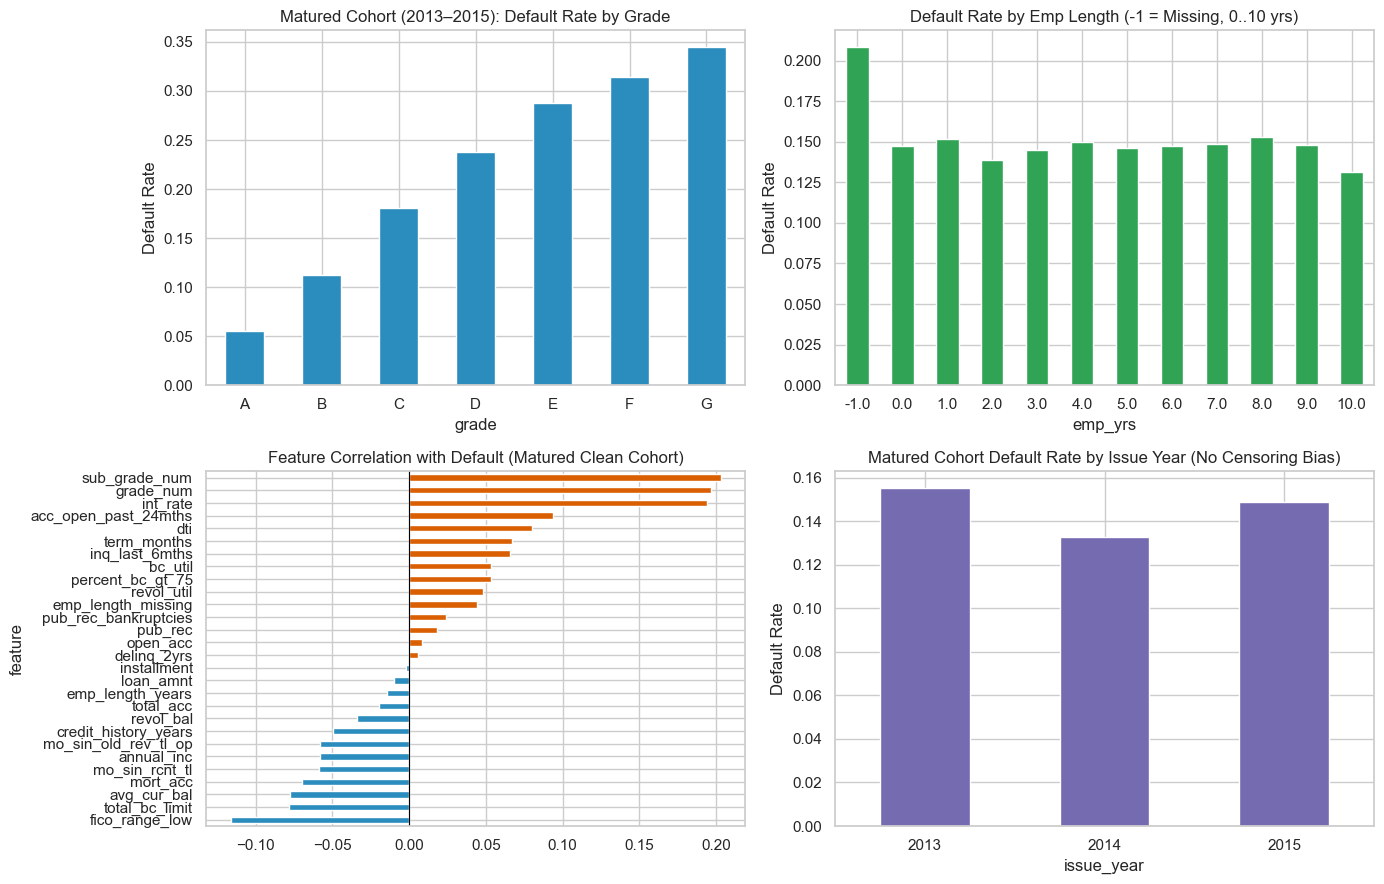

In [8]:
# Stage 2 EDA verification on the clean matured cohort
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

s2_clean.groupby("grade")["default"].mean().reindex(GRADE_ORDER).plot(kind="bar", ax=axes[0, 0], color="#2b8cbe")
axes[0, 0].set_title("Matured Cohort (2013–2015): Default Rate by Grade")
axes[0, 0].set_ylabel("Default Rate")
axes[0, 0].tick_params(axis="x", rotation=0)

emp_plot = s2_clean.assign(emp_yrs=s2_clean["emp_length_years"].fillna(-1))
emp_plot.groupby("emp_yrs")["default"].mean().plot(kind="bar", ax=axes[0, 1], color="#31a354")
axes[0, 1].set_title("Default Rate by Emp Length (-1 = Missing, 0..10 yrs)")
axes[0, 1].set_ylabel("Default Rate")
axes[0, 1].tick_params(axis="x", rotation=0)

corr_s = col_audit_df.dropna(subset=["corr_with_default"]).set_index("feature")["corr_with_default"].sort_values()
corr_s.plot(kind="barh", ax=axes[1, 0], color=["#2b8cbe" if v < 0 else "#d95f02" for v in corr_s])
axes[1, 0].set_title("Feature Correlation with Default (Matured Clean Cohort)")
axes[1, 0].axvline(0, color="black", linewidth=0.8)

s2_clean.groupby("issue_year")["default"].agg(["mean", "size"]).rename(columns={"mean": "default_rate"})["default_rate"].plot(
    kind="bar", ax=axes[1, 1], color="#756bb1"
)
axes[1, 1].set_title("Matured Cohort Default Rate by Issue Year (No Censoring Bias)")
axes[1, 1].set_ylabel("Default Rate")
axes[1, 1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()